In [1]:
import atexit
import hashlib
import os
import subprocess
import sys
import tempfile
import zipfile
from pathlib import Path

from IPython.display import clear_output, display
from jupyter_client import KernelManager
from jupyter_client.kernelspec import KernelSpecManager

working = Path("/kaggle/working")
inputs = Path("/kaggle/input")
prefix = working / "seminar-env"
marker = prefix / ".seminar-pack-id"
archive_id = "b33b26f11d53e728e250a66deac7fda269855f1ef407807bc3f115aabee40a8d"
setup_hash = "e4a9906b4019d419e74b81fed8e41110ec1d6111b09e1848cdf5d65730d1059e"

if not (marker.is_file() and marker.read_text().strip() == archive_id):
    with tempfile.TemporaryDirectory(dir=working) as scratch:
        installer = next((p for p in inputs.rglob("setup-seminar.sh")
                          if p.with_name("seminar-linux-64.condapack").is_file()
                          and hashlib.sha256(p.read_bytes()).hexdigest() == setup_hash), None)
        if installer is None:
            bundle = next(inputs.rglob("seminar-kaggle-linux64.zip"), None)
            if bundle is None:
                raise FileNotFoundError("Подключите Dataset с архивом seminar-kaggle-linux64.zip через Add Input.")
            with zipfile.ZipFile(bundle) as z:
                installer = Path(z.extract("setup-seminar.sh", scratch))
                if hashlib.sha256(installer.read_bytes()).hexdigest() != setup_hash:
                    raise ValueError("Версия установщика отличается от версии архива для этого семинара.")
                z.extract("seminar-linux-64.condapack", scratch)
        print("Распаковываю среду семинара…", flush=True)
        install = subprocess.run(["bash", str(installer)], text=True,
                                 stdout=subprocess.PIPE, stderr=subprocess.STDOUT)
        print(install.stdout, end="")
        install.check_returncode()

# Все учебные ячейки используют одно ядро из архива. Повторный запуск сохраняет его состояние.
if "seminar_kernel" not in globals() or not seminar_kernel.is_alive():
    specs = KernelSpecManager(kernel_dirs=[str(prefix / "share/jupyter/kernels")])
    seminar_kernel = KernelManager(kernel_name="seminar-svd", kernel_spec_manager=specs)
    kernel_env = {k: v for k, v in os.environ.items() if k not in ("PYTHONHOME", "PYTHONPATH")}
    kernel_env.update(PATH=f"{prefix}/bin:{os.environ['PATH']}", PYTHONNOUSERSITE="1", CUPY_TF32="0",
                      MPLBACKEND="module://matplotlib_inline.backend_inline")
    seminar_kernel.start_kernel(cwd=str(prefix / "share/seminar"), env=kernel_env)
    seminar_client = seminar_kernel.client()
    seminar_client.start_channels()
    try:
        seminar_client.wait_for_ready(timeout=120)
    except BaseException:
        seminar_client.stop_channels()
        seminar_kernel.shutdown_kernel(now=True)
        raise
    atexit.register(seminar_kernel.shutdown_kernel, now=True)
    atexit.register(seminar_client.stop_channels)

def show_seminar_output(msg):
    kind, content = msg["msg_type"], msg["content"]
    if kind == "stream":
        stream = sys.stderr if content["name"] == "stderr" else sys.stdout
        stream.write(content["text"])
        stream.flush()
    elif kind in ("display_data", "execute_result"):
        display(content["data"], raw=True, metadata=content.get("metadata", {}))
    elif kind == "clear_output":
        clear_output(wait=content.get("wait", False))

def seminar(line, cell):
    try:
        reply = seminar_client.execute_interactive(cell, allow_stdin=False, timeout=900,
                                                  output_hook=show_seminar_output)
    except (KeyboardInterrupt, TimeoutError):
        seminar_kernel.interrupt_kernel()
        raise
    result = reply["content"]
    if result["status"] != "ok":
        raise RuntimeError("\n".join(result.get("traceback", [])) or str(result["status"]))

get_ipython().register_magic_function(seminar, magic_kind="cell", magic_name="seminar")
seminar("", "import sys\nassert sys.prefix == '/kaggle/working/seminar-env', sys.executable\nprint('Python семинара:', sys.executable)")
print("Готово. Следующей можно запустить ячейку проверки CuPy.")

Распаковываю среду семинара…
Распаковка Linux x86-64 в /kaggle/working/seminar-env
/kaggle/input/competitions/2026-2027-mod-ai-svd-decomposition/seminar-linux-64.condapack: OK
Installed kernelspec seminar-svd in /kaggle/working/seminar-env/share/jupyter/kernels/seminar-svd
Python: /kaggle/working/seminar-env/bin/python


[IPKernelApp] WARNING | Kernel is running over TCP without encryption. All communication (including code and outputs) is sent in plain text and is susceptible to eavesdropping. Use IPC transport or launch with kernel manager-provisioned CurveZMQ keys to enable transport encryption.


Python семинара: /kaggle/working/seminar-env/bin/python
Готово. Следующей можно запустить ячейку проверки CuPy.


# Семинар. От вычислений на CPU и GPU к сингулярному разложению

На семинаре разберём, что делают три множителя в формуле $A=U\Sigma V^\top$ и как с их помощью решать задачи на реальных данных. Начнём с операций над массивами на CPU и GPU. Затем на бумаге разложим две матрицы — квадратную и прямоугольную. Прямоугольная матрица появится снова, когда мы будем подбирать прямую по трём наблюдениям. Сравним ручной ответ с NumPy и градиентным спуском, а затем повторим расчёт на наборе diabetes.

Во второй части будем выбирать, какие компоненты SVD сохранить при подавлении шума, сжатии фотографии, выделении фона в видео и восстановлении лиц. В домашней работе предстоит написать алгоритм SVD для произвольной матрицы.

Материалы семинара находятся в рабочем каталоге учебного ядра `/kaggle/working/seminar-env/share/seminar`.

### Проверка CuPy на GPU

Эту ячейку можно выполнить сразу после настройки и в любой момент запустить повторно. Она покажет путь к Python и модель видеокарты, посчитает на GPU квадраты норм строк и произведение двух матриц, затем сверит оба результата с NumPy. Для CPU-сессии будет выведена причина пропуска.

Дальше запускайте учебные ячейки по порядку с помощью **Shift+Enter**. Первая строка `%%seminar` направляет код в одно и то же ядро среды. Все ячейки уже размечены. Чтобы попробовать свой пример, добавьте `%%seminar` в первую строку новой ячейки.

In [2]:
%%seminar
import sys
from importlib.metadata import version
import numpy as np

def check_cupy_gpu():
    print(f"Python: {sys.executable}\nCuPy: {version('cupy-cuda13x')}")
    try:
        import cupy as cp
        device_count = cp.cuda.runtime.getDeviceCount()
    except (ImportError, OSError, RuntimeError) as error:
        print(f"Проверка GPU пропущена. Проверьте выбор GPU в Settings → Accelerator и совместимость с CUDA 13.\nПричина: {error}")
        return False
    if device_count == 0:
        print("CUDA-устройств не обнаружено. Включите GPU в Settings → Accelerator.")
        return False

    device = cp.cuda.Device()
    name = cp.cuda.runtime.getDeviceProperties(device.id)["name"]
    if isinstance(name, bytes):
        name = name.decode()
    print(f"GPU {device.id}: {name}  |  CUDA driver: {cp.cuda.runtime.driverGetVersion()}  |  CUDA runtime: {cp.cuda.runtime.runtimeGetVersion()}")

    x_cpu = np.arange(12, dtype=np.float32).reshape(3, 4)
    x_gpu = cp.asarray(x_cpu)
    row_norms = cp.sum(x_gpu * x_gpu, axis=1)
    gram = x_gpu @ x_gpu.T
    cp.cuda.get_current_stream().synchronize()
    np.testing.assert_allclose(cp.asnumpy(row_norms), np.sum(x_cpu**2, axis=1))
    np.testing.assert_allclose(cp.asnumpy(gram), x_cpu @ x_cpu.T)
    print(f"CuPy работает на GPU. Квадраты норм строк: {cp.asnumpy(row_norms)}. Произведение матриц совпало с NumPy.")
    return True

cupy_gpu_ok = check_cupy_gpu()

Python: /kaggle/working/seminar-env/bin/python
CuPy: 14.2.0
GPU 0: Tesla T4  |  CUDA driver: 13000  |  CUDA runtime: 13020
CuPy работает на GPU. Квадраты норм строк: [ 14. 126. 366.]. Произведение матриц совпало с NumPy.


## 1. Вычисления на CPU и GPU

In [4]:
%%seminar
import json, platform, time, os
os.environ["CUPY_TF32"] = "0"  # политика точности задаётся до импорта CuPy
import numpy as np
import scipy
from scipy import linalg
import sklearn
from sklearn.datasets import load_diabetes, load_sample_image
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
import matplotlib
import matplotlib.pyplot as plt
import numba
from numba import njit

np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({'figure.figsize': (9, 4.5), 'axes.grid': True, 'grid.alpha': .22})
print('Python', platform.python_version(), '| NumPy', np.__version__, '| SciPy', scipy.__version__,
      '| scikit-learn', sklearn.__version__, '| Numba', numba.__version__, '| Matplotlib', matplotlib.__version__)

Python 3.12.16 | NumPy 2.3.5 | SciPy 1.18.1 | scikit-learn 1.9.1 | Numba 0.68.1 | Matplotlib 3.11.2


### Массивы NumPy, оси и произведения

Строки матрицы — наблюдения, столбцы — признаки. `axis=0` сворачивает строки и даёт статистику для каждого столбца. Broadcasting вычитает вектор средних из каждой строки. `@` — матричное произведение, `*` — поэлементное. Обычный срез делит память с исходным массивом; `.copy()` создаёт независимые данные.

In [5]:
%%seminar
A_demo = np.array([[1., 2., 0.], [3., 4., 0.], [5., 6., 0.]])
column_mean = A_demo.mean(axis=0)
centered_demo = A_demo - column_mean[None, :]
print('A:', A_demo.shape, 'mean:', column_mean.shape, 'centered:', centered_demo.shape)
print('A @ A.T:', (A_demo @ A_demo.T).shape, 'A * A:', (A_demo * A_demo).shape)
assert np.allclose(centered_demo.mean(axis=0), 0)
assert (A_demo @ A_demo.T).shape == (3, 3)

A: (3, 3) mean: (3,) centered: (3, 3)
A @ A.T: (3, 3) A * A: (3, 3)


In [6]:
%%seminar
view = A_demo[:, :2]                 # срез обычно делит память
copy = A_demo[:, :2].copy()          # самостоятельные данные
assert np.shares_memory(view, A_demo) and not np.shares_memory(copy, A_demo)
print('view shares memory:', np.shares_memory(view, A_demo), '| copy shares memory:', np.shares_memory(copy, A_demo))

view shares memory: True | copy shares memory: False


### Одна операция на CPU в NumPy и Numba

Вычислим квадрат длины каждой строки $q_i=\sum_j X_{ij}^2$. В NumPy перемножим элементы массива и сложим результат по столбцам каждой строки с помощью `sum(axis=1)`. В Numba ту же сумму запишем двойным циклом. Сверим результаты и измерим медиану десяти прогретых запусков. Первый вызов Numba засечём отдельно, поскольку в него входит компиляция функции.

In [7]:
%%seminar
rows = np.random.default_rng(7).normal(size=(1024, 128)).astype(np.float64)

def row_squared_norms_numpy(a):
    return np.sum(a * a, axis=1)

@njit
def row_squared_norms_numba(a):
    out = np.empty(a.shape[0], dtype=np.float64)
    for i in range(a.shape[0]):
        total = 0.0
        for j in range(a.shape[1]):
            total += a[i, j] * a[i, j]
        out[i] = total
    return out

q_numpy = row_squared_norms_numpy(rows)
started = time.perf_counter()
q_numba = row_squared_norms_numba(rows)
numba_first = time.perf_counter() - started
assert np.allclose(q_numpy, q_numba, rtol=1e-12, atol=1e-12)
print(f"Формы {rows.shape} → {q_numba.shape}. Максимальное расхождение {np.max(np.abs(q_numpy - q_numba)):.2e}")
print(f"Numba, первый вызов с компиляцией: {numba_first * 1000:.2f} мс")
for name, compute in (("NumPy", row_squared_norms_numpy), ("Numba", row_squared_norms_numba)):
    durations = []
    for _ in range(10):
        started = time.perf_counter()
        compute(rows)
        durations.append(time.perf_counter() - started)
    print(f"{name}, медиана 10 прогретых вызовов: {np.median(durations) * 1000:.3f} мс")

Формы (1024, 128) → (1024,). Максимальное расхождение 1.42e-13
Numba, первый вызов с компиляцией: 756.51 мс
NumPy, медиана 10 прогретых вызовов: 0.186 мс
Numba, медиана 10 прогретых вызовов: 0.146 мс


### Та же операция на GPU с CuPy

Перенесём массив на GPU и запишем сумму квадратов так же, как в NumPy. Отдельно измерим три этапа — передачу массива на GPU, вычисление и возврат результата на CPU. Синхронизация гарантирует, что к моменту замера устройство закончило работу. Сравним итоговый вектор с `q_numpy`. При отсутствии CuPy или CUDA ячейка выведет причину пропуска.

{'status': 'исполнено на CUDA', 'device': 'Tesla T4', 'transfer_to_gpu_seconds': 0.0010752460000276187, 'compute_seconds': 0.00023317699992730923, 'transfer_to_cpu_seconds': 0.0001576709998971637, 'max_abs_error': 5.684341886080802e-14}


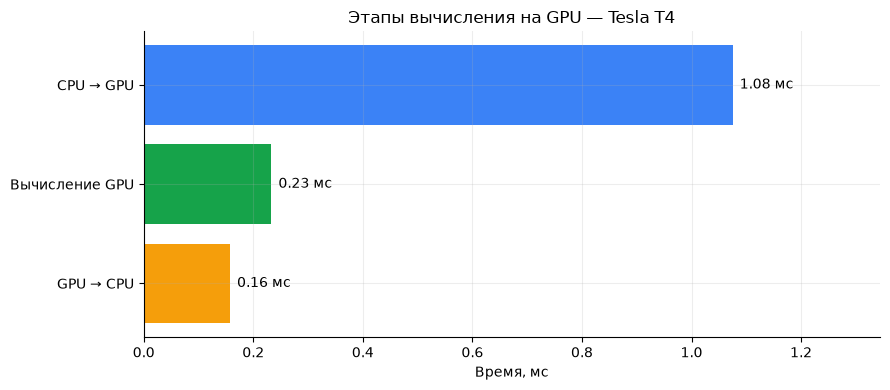

Общее время: 1.47 мс
Максимальная ошибка: 5.68e-14


In [20]:

%%seminar
import cupy as cp
import time
import numpy as np

device = cp.cuda.runtime.getDeviceProperties(0)["name"]
device = device.decode() if isinstance(device, bytes) else device

t = time.perf_counter()
d_rows = cp.asarray(rows)
cp.cuda.Stream.null.synchronize()
h2d = time.perf_counter() - t

cp.sum(d_rows ** 2, axis=1)
cp.cuda.Stream.null.synchronize()

t = time.perf_counter()
d_result = cp.sum(d_rows ** 2, axis=1)
cp.cuda.Stream.null.synchronize()
compute = time.perf_counter() - t

t = time.perf_counter()
q_gpu = cp.asnumpy(d_result)
d2h = time.perf_counter() - t

gpu_metrics = {
    "status": "исполнено на CUDA",
    "device": device,
    "transfer_to_gpu_seconds": h2d,
    "compute_seconds": compute,
    "transfer_to_cpu_seconds": d2h,
    "max_abs_error": float(np.max(np.abs(q_gpu - q_numpy)))
}

print(gpu_metrics)


labels = ["CPU → GPU", "Вычисление GPU", "GPU → CPU"]
times = np.array([h2d, compute, d2h]) * 1000

fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.barh(labels, times, color=["#3b82f6", "#16a34a", "#f59e0b"])

ax.invert_yaxis()
ax.bar_label(bars, fmt="%.2f мс", padding=5)
ax.set_xlim(0, max(times) * 1.25)
ax.set_xlabel("Время, мс")
ax.set_title(f"Этапы вычисления на GPU — {device}")
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

print(f"Общее время: {sum(times):.2f} мс")
print(f"Максимальная ошибка: {gpu_metrics['max_abs_error']:.2e}")


### При каком размере матриц окупается передача на GPU?

Для достаточно больших плотных матриц сравним одну и ту же операцию `A @ B` в `float32` на CPU (NumPy BLAS) и CUDA (CuPy). В текущем ноутбуке по умолчанию `n=2048`, CPU использует до 12 логических потоков через `threadpoolctl`; после двух прогревов берём медиану семи повторов. GPU-время **только вычисления** измеряется CUDA events на уже размещённых матрицах. **Полный путь** измеряется настенными часами с синхронизацией и включает `cp.asarray(A)`, `cp.asarray(B)`, произведение и `cp.asnumpy(C)`. `CUPY_TF32=0` задан до импорта CuPy. Оба результата сверяем по относительной ошибке Фробениуса.

{'status': 'исполнено на CUDA', 'n': 2048, 'dtype': 'float32', 'cpu_threads': 4, 'cpu_median_seconds': np.float64(0.07519950999994762), 'gpu_resident_median_seconds': np.float64(0.006090752124786377), 'gpu_roundtrip_median_seconds': np.float64(0.016814200999988316), 'resident_speedup': np.float64(12.346506385298863), 'roundtrip_speedup': np.float64(4.472380816667998), 'relative_frobenius_error': 6.057952059008572e-07}


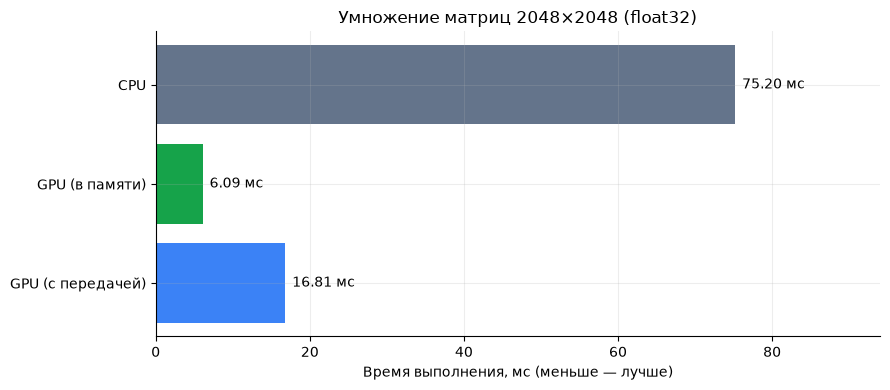

GPU без передачи: ×12.35
GPU с передачей: ×4.47
Относительная ошибка: 6.06e-07


In [19]:
%%seminar
import os
import time
import numpy as np
import matplotlib.pyplot as plt
from threadpoolctl import threadpool_limits

if gpu_metrics["status"] == "исполнено на CUDA":
    n = 2048
    threads = min(12, os.cpu_count() or 1)
    rng = np.random.default_rng(20261111 + n)
    a = rng.standard_normal((n, n), dtype=np.float32)
    b = rng.standard_normal((n, n), dtype=np.float32)

    # CPU
    with threadpool_limits(limits=threads, user_api="blas"):
        for _ in range(2):
            a @ b

        cpu_times = []
        for _ in range(7):
            t = time.perf_counter()
            c_cpu = a @ b
            cpu_times.append(time.perf_counter() - t)

    # GPU: данные уже в видеопамяти
    da, db = cp.asarray(a), cp.asarray(b)

    for _ in range(2):
        da @ db
    cp.cuda.Stream.null.synchronize()

    gpu_times = []
    for _ in range(7):
        start, end = cp.cuda.Event(), cp.cuda.Event()
        start.record()
        dc = da @ db
        end.record()
        end.synchronize()
        gpu_times.append(cp.cuda.get_elapsed_time(start, end) / 1000)

    c_gpu = cp.asnumpy(dc)
    error = np.linalg.norm(c_gpu.astype("float64") - c_cpu.astype("float64"))
    error /= np.linalg.norm(c_cpu.astype("float64"))

    # GPU: с копированием CPU → GPU → CPU
    transfer_times = []
    for i in range(9):
        t = time.perf_counter()
        result = cp.asnumpy(cp.asarray(a) @ cp.asarray(b))
        cp.cuda.Stream.null.synchronize()

        if i >= 2:
            transfer_times.append(time.perf_counter() - t)

    cpu_ms = np.median(cpu_times) * 1000
    gpu_ms = np.median(gpu_times) * 1000
    transfer_ms = np.median(transfer_times) * 1000

    matmul_metrics = {
        "status": "исполнено на CUDA",
        "n": n,
        "dtype": "float32",
        "cpu_threads": threads,
        "cpu_median_seconds": cpu_ms / 1000,
        "gpu_resident_median_seconds": gpu_ms / 1000,
        "gpu_roundtrip_median_seconds": transfer_ms / 1000,
        "resident_speedup": cpu_ms / gpu_ms,
        "roundtrip_speedup": cpu_ms / transfer_ms,
        "relative_frobenius_error": float(error),
    }

    print(matmul_metrics)

    # Визуализация
    labels = ["CPU", "GPU (в памяти)", "GPU (с передачей)"]
    times = [cpu_ms, gpu_ms, transfer_ms]

    fig, ax = plt.subplots(figsize=(9, 4))
    bars = ax.barh(labels, times, color=["#64748b", "#16a34a", "#3b82f6"])

    ax.invert_yaxis()
    ax.bar_label(bars, labels=[f"{v:.2f} мс" for v in times], padding=5)
    ax.set_xlim(0, max(times) * 1.25)
    ax.set_xlabel("Время выполнения, мс (меньше — лучше)")
    ax.set_title(f"Умножение матриц {n}×{n} (float32)")
    ax.spines[["top", "right"]].set_visible(False)

    plt.tight_layout()
    plt.show()

    print(f"GPU без передачи: ×{cpu_ms / gpu_ms:.2f}")
    print(f"GPU с передачей: ×{cpu_ms / transfer_ms:.2f}")
    print(f"Относительная ошибка: {error:.2e}")

else:
    matmul_metrics = {"status": gpu_metrics["status"]}
    print(matmul_metrics)


## 2. SVD квадратной матрицы вручную

**Задача.** Найдите сингулярное разложение матрицы
$$
A=\begin{pmatrix}2&1\\-1&-2\end{pmatrix}.
$$
Представьте, что $A$ действует на единичный круг. Какие два перпендикулярных направления $v_1,v_2$ она переводит в направления $u_1,u_2$, которые тоже перпендикулярны? Во сколько раз она растягивает каждое из них?

Запишите $A=U\Sigma V^\top$, где столбцы $V$ и $U$ — найденные единичные векторы, а на диагонали $\Sigma$ стоят коэффициенты растяжения $\sigma_1\geq\sigma_2\geq 0$.

In [23]:
%%seminar
svd_square = np.array([[2., 1.], [-1., -2.]])
np.linalg.svd(svd_square)

SVDResult(U=array([[-0.7071,  0.7071],
       [ 0.7071,  0.7071]]), S=array([3., 1.]), Vh=array([[-0.7071, -0.7071],
       [ 0.7071, -0.7071]]))

## 3. SVD прямоугольной матрицы вручную

**Задача.** Найти сингулярное разложение матрицы
$$
Z=\begin{pmatrix}3&3\\0&0\\4&4\end{pmatrix}.
$$

Произведение трёх найденных матриц:
[[ 2.  1.]
 [-1. -2.]]


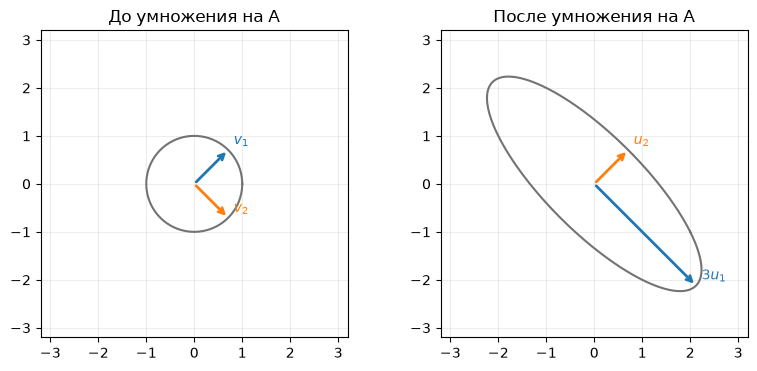

In [10]:
%%seminar
svd_square = np.array([[2., 1.], [-1., -2.]])
square_u = np.array([[1., 1.], [-1., 1.]]) / np.sqrt(2)
square_sigma = np.diag([3., 1.])
square_vt = np.array([[1., 1.], [1., -1.]]) / np.sqrt(2)

square_reconstructed = square_u @ square_sigma @ square_vt
assert np.allclose(square_u.T @ square_u, np.eye(2))
assert np.allclose(square_vt @ square_vt.T, np.eye(2))
assert np.allclose(square_reconstructed, svd_square)
print("Произведение трёх найденных матриц:")
print(square_reconstructed)

theta = np.linspace(0, 2 * np.pi, 240)
circle = np.stack((np.cos(theta), np.sin(theta)))
fig, axes = plt.subplots(1, 2, figsize=(8, 3.6), layout="constrained")
for ax, curve, arrows, labels, title in (
    (axes[0], circle, square_vt.T, (r"$v_1$", r"$v_2$"), "До умножения на A"),
    (axes[1], svd_square @ circle, square_u @ square_sigma,
     (r"$3u_1$", r"$u_2$"), "После умножения на A"),
):
    ax.plot(*curve, color="0.45")
    for arrow, label, color in zip(arrows.T, labels, ("tab:blue", "tab:orange")):
        ax.annotate("", xy=arrow, xytext=(0, 0), arrowprops=dict(arrowstyle="->", color=color, lw=2))
        ax.annotate(label, arrow, xytext=(4, 4), textcoords="offset points", color=color)
    ax.set(xlim=(-3.2, 3.2), ylim=(-3.2, 3.2), aspect="equal", title=title)
plt.show()

**Задача.** Возьмём три значения признака $x=-1,0,1$ и добавим столбец единиц. Получится матрица
$$
Z=\begin{pmatrix}-1&1\\0&1\\1&1\end{pmatrix}.
$$
Она переводит вектор двух коэффициентов $(a,b)^\top$ в три значения прямой $ax+b$. На бумаге найдите сингулярные значения и направления $Z$, затем укажите размеры $U$, $\Sigma$ и $V^\top$ для компактного и полного разложений. Подсказка: какие скалярные произведения двух столбцов входят в $Z^\top Z$?

In [11]:
%%seminar
svd_rect = np.array([[-1., 1.], [0., 1.], [1., 1.]])
rect_u1 = np.array([1., 1., 1.]) / np.sqrt(3)
rect_u2 = np.array([-1., 0., 1.]) / np.sqrt(2)
rect_u3 = np.array([1., -2., 1.]) / np.sqrt(6)
rect_u = np.column_stack((rect_u1, rect_u2))
rect_sigma = np.diag([np.sqrt(3), np.sqrt(2)])
rect_vt = np.array([[0., 1.], [1., 0.]])

rect_u_full = np.column_stack((rect_u, rect_u3))
rect_sigma_full = np.vstack((rect_sigma, np.zeros((1, 2))))
assert np.allclose(rect_u_full.T @ rect_u_full, np.eye(3))
assert np.allclose(rect_vt @ rect_vt.T, np.eye(2))
assert np.allclose(rect_u @ rect_sigma @ rect_vt, svd_rect)
assert np.allclose(rect_u_full @ rect_sigma_full @ rect_vt, svd_rect)
print("Размеры факторов (U, Σ, Vᵀ)")
print("Компактная форма:", rect_u.shape, rect_sigma.shape, rect_vt.shape)
print("Полная форма:    ", rect_u_full.shape, rect_sigma_full.shape, rect_vt.shape)

Размеры факторов (U, Σ, Vᵀ)
Компактная форма: (3, 2) (2, 2) (2, 2)
Полная форма:     (3, 3) (3, 2) (2, 2)


## 4. Табличная задача о заказах в кафе

В кафе записали число заказов за три часовых интервала. Обозначим через $x$ время начала интервала в часах относительно полудня, через $y$ — число заказов за интервал.

| Начало интервала | $x$, ч | $y$, заказов |
|---|---:|---:|
| 11:00 | −1 | 10 |
| 12:00 | 0 | 13 |
| 13:00 | 1 | 22 |

Подберём по этим наблюдениям прямую $\hat y=ax+b$. Здесь $b$ — прогноз для полуденного интервала, а $a$ — изменение прогноза при сдвиге на час. Расположим коэффициенты в порядке $w=(a,b)^\top$. Получается знакомая матрица $Z=[x,\mathbf 1]$ размера $3\times2$.

**Задача.** Найдите $w$, минимизирующий $L(w)=\|Zw-y\|_2^2/(2n)$ при $n=3$. Какой прогноз для полудня получится, если учесть все три наблюдения?

### На бумаге через SVD

Из предыдущего разложения берём два направления в пространстве наблюдений — $\mathbf1/\sqrt3$ и $x/\sqrt2$. Их сингулярные значения — $\sqrt3$ и $\sqrt2$. Чтобы найти коэффициент прямой, проецируем $y$ на соответствующее единичное направление и делим результат на его сингулярное значение.

$$
b=\frac{(\mathbf1/\sqrt3)^\top y}{\sqrt3}
  =\frac{10+13+22}{3}=15,\qquad
a=\frac{(x/\sqrt2)^\top y}{\sqrt2}
  =\frac{-10+22}{2}=6.
$$

Прямая $\hat y=6x+15$ даёт прогнозы $(9,15,21)$. Невязка $Zw-y=(-1,2,-1)^\top$ ортогональна обоим столбцам $Z$. Поэтому изменение наклона или свободного члена уже не уменьшит сумму квадратов ошибок. Средняя квадратичная ошибка равна $\mathrm{MSE}=(1+4+1)/3=2$, а $L=1$. Вектор ошибки направлен вдоль $u_3$ из предыдущей задачи.

In [13]:
%%seminar
table_Z = svd_rect  # столбцы x и 1 из предыдущей задачи
table_y = np.array([10., 13., 22.])
table_w_hand = np.array([6., 15.])  # наклон, свободный член

### С помощью NumPy

Передаём те же три наблюдения в `np.linalg.lstsq`. Первый элемент результата содержит коэффициенты в порядке столбцов матрицы $Z$.

In [14]:
%%seminar
table_w_numpy = np.linalg.lstsq(table_Z, table_y, rcond=None)[0]
print("Наклон и свободный член:", table_w_numpy)

Наклон и свободный член: [ 6. 15.]


### С помощью градиентного спуска

Для той же функции потерь $\nabla L(w)=Z^\top(Zw-y)/3$. Начнём с $w_0=(0,0)^\top$ и возьмём шаг $\eta=1$, поскольку у гессиана $Z^\top Z/3=\operatorname{diag}(2/3,1)$ наибольшее собственное значение равно единице.

Первый градиент равен $-Z^\top y/3=(-4,-15)^\top$, поэтому $w_1=w_0-\eta\nabla L(w_0)=(4,15)^\top$. Свободный член уже совпал с ручным ответом. Проследите по циклу, как обновляется наклон.

In [15]:
%%seminar
table_w_gd = np.zeros(2)
table_eta = 1.0
table_grad_tol = 1e-10

for table_step in range(100):
    table_residual = table_Z @ table_w_gd - table_y
    table_grad = table_Z.T @ table_residual / len(table_y)
    if np.linalg.norm(table_grad) < table_grad_tol:
        break
    table_w_gd -= table_eta * table_grad
    if table_step == 0:
        print("Первый градиент:", table_grad, "| веса после шага:", table_w_gd)
else:
    raise RuntimeError("Градиентный спуск не достиг заданной точности")

print("Шагов до остановки:", table_step)
for table_method, table_w in (("Вручную", table_w_hand),
                             ("NumPy", table_w_numpy),
                             ("Градиентный спуск", table_w_gd)):
    table_pred = table_Z @ table_w
    table_mse = np.mean((table_pred - table_y)**2)
    print(f"{table_method:18s}  w = {table_w.round(4)},  прогнозы = {table_pred.round(4)},  MSE = {table_mse:.4f}")
    np.testing.assert_allclose(table_w, table_w_hand, rtol=0, atol=1e-8)
    np.testing.assert_allclose(table_pred, [9, 15, 21], rtol=0, atol=1e-8)
    np.testing.assert_allclose(table_mse, 2.0)

Первый градиент: [ -4. -15.] | веса после шага: [ 4. 15.]
Шагов до остановки: 23
Вручную             w = [ 6. 15.],  прогнозы = [ 9. 15. 21.],  MSE = 2.0000
NumPy               w = [ 6. 15.],  прогнозы = [ 9. 15. 21.],  MSE = 2.0000
Градиентный спуск   w = [ 6. 15.],  прогнозы = [ 9. 15. 21.],  MSE = 2.0000


В полдень модель предсказывает **15 заказов**, хотя в таблице записано 13. Прямая учитывает соседние интервалы. В следующей задаче, на данных diabetes, признаков станет десять. После весов признаков по-прежнему идёт свободный член.

## 5. Линейная регрессия на данных diabetes

Теперь предсказываем числовой показатель прогрессирования заболевания через год. В `load_diabetes(scaled=False)` каждому из 442 наблюдений соответствуют десять исходных признаков. Разбиваем 331/111 с фиксированным seed. `StandardScaler` обучаем **только** на train; test получает лишь `transform`. Во все методы подаём один дизайн $Z=[X_{scaled},\mathbf 1]$ и минимизируем $L(w)=\|Zw-y\|_2^2/(2n)$ **без регуляризации**. Последний столбец — свободный член; для `LinearRegression` поэтому `fit_intercept=False`.

In [16]:
%%seminar
data = load_diabetes(scaled=False)
X, y = np.asarray(data.data, dtype=float), np.asarray(data.target, dtype=float)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.25, random_state=43)
scaler = StandardScaler().fit(X_train)
Z_train = np.column_stack((scaler.transform(X_train), np.ones(len(X_train))))
Z_test = np.column_stack((scaler.transform(X_test), np.ones(len(X_test))))
assert X.shape == (442,10) and Z_train.shape == (331,11) and Z_test.shape == (111,11)
assert np.allclose(Z_train[:,:-1].mean(axis=0), 0, atol=1e-12)
print('data:', X.shape, '| train design:', Z_train.shape, '| test design:', Z_test.shape)
print('train-only scaler means:', scaler.mean_)

data: (442, 10) | train design: (331, 11) | test design: (111, 11)
train-only scaler means: [ 48.8489   1.4502  26.4154  94.2084 189.7009 116.7205  49.3369   4.1144
   4.6365  91.1269]


### Как выглядят данные diabetes?

Посмотрим на 331 наблюдение обучающей выборки до стандартизации. Гистограмма показывает, как распределён показатель прогрессирования заболевания через год. В центре каждая точка соответствует одному человеку. По горизонтали отложен исходный индекс массы тела (ИМТ, `bmi`), по вертикали — показатель через год.

Справа показана корреляция Пирсона каждого из десяти признаков с целью. Признак `bp` обозначает среднее артериальное давление, а `s1`–`s6` — показатели анализа крови. **Вопрос для обсуждения.** Как сильно различаются значения цели у людей с ИМТ около 30, хотя общая связь ИМТ с целью положительна?

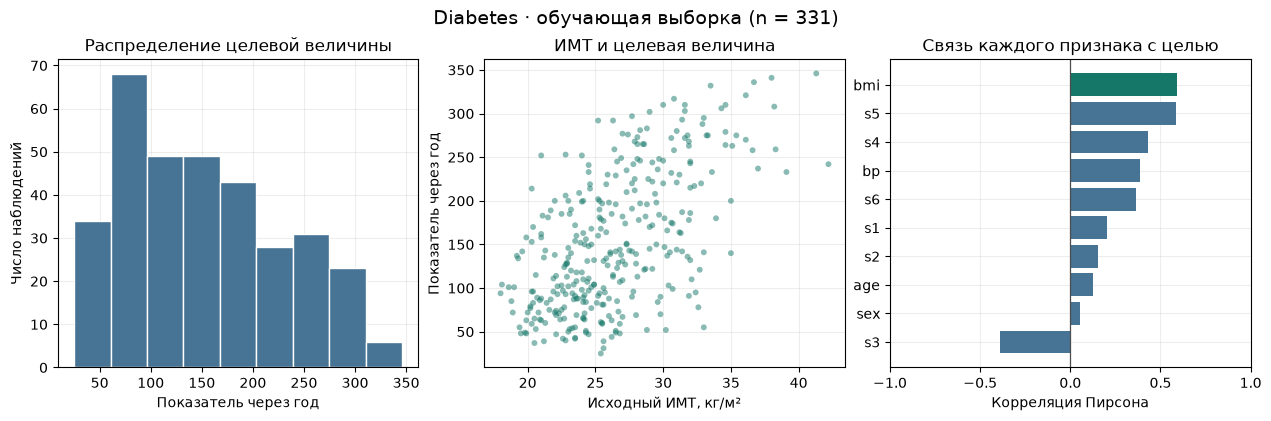

In [17]:
%%seminar
# Для обзора используем исходные значения признаков обучающей выборки.
bmi_index = data.feature_names.index("bmi")
feature_target_r = np.corrcoef(np.column_stack((X_train, y_train)), rowvar=False)[-1, :-1]
feature_order = np.argsort(feature_target_r)

fig, (distribution_ax, bmi_ax, correlation_ax) = plt.subplots(
    1, 3, figsize=(12.6, 4.1), layout="constrained"
)
blue, teal = "#477394", "#147768"

distribution_ax.hist(y_train, bins="fd", color=blue, edgecolor="white")
distribution_ax.set(
    title="Распределение целевой величины",
    xlabel="Показатель через год", ylabel="Число наблюдений",
)

bmi_ax.scatter(X_train[:, bmi_index], y_train, s=18, color=teal, alpha=0.5, edgecolors="none")
bmi_ax.set(
    title="ИМТ и целевая величина",
    xlabel="Исходный ИМТ, кг/м²", ylabel="Показатель через год",
)

feature_names = np.asarray(data.feature_names)[feature_order]
bar_colors = [teal if name == "bmi" else blue for name in feature_names]
correlation_ax.barh(feature_names, feature_target_r[feature_order], color=bar_colors)
correlation_ax.axvline(0, color="0.3", linewidth=0.9)
correlation_ax.set(
    title="Связь каждого признака с целью",
    xlabel="Корреляция Пирсона", xlim=(-1, 1), xticks=[-1, -0.5, 0, 0.5, 1],
)

for ax in (distribution_ax, bmi_ax, correlation_ax):
    ax.set_axisbelow(True)
fig.suptitle(f"Diabetes · обучающая выборка (n = {len(y_train)})", fontsize=14)
plt.show()

### Библиотечные решения

Сравниваем `np.linalg.pinv`, `scipy.linalg.pinv`, `scipy.linalg.lstsq` и `sklearn.linear_model.LinearRegression` на одном обучающем дизайне. Порог `1e-12` в каждой псевдообратной и `lstsq` одинаков; `LinearRegression(tol=1e-12)` использует библиотечный dense solver. Проверяем ранг и прогнозы, а не отдельные сингулярные векторы.

In [18]:
%%seminar
start=time.perf_counter()
w_np_pinv=np.linalg.pinv(Z_train,rcond=1e-12)@y_train
numpy_pinv_seconds=time.perf_counter()-start
w_sp_pinv=linalg.pinv(Z_train,atol=0,rtol=1e-12)@y_train
w_scipy,_,scipy_rank,_=linalg.lstsq(Z_train,y_train,cond=1e-12)
sk_model=LinearRegression(fit_intercept=False,positive=False,tol=1e-12).fit(Z_train,y_train)
w_sklearn=sk_model.coef_
print('SciPy/sklearn rank:',scipy_rank,sk_model.rank_)
print('max test prediction gap, NumPy/SciPy pinv:',np.max(np.abs(Z_test@w_np_pinv-Z_test@w_sp_pinv)))
assert scipy_rank==sk_model.rank_==11
for w in (w_np_pinv,w_sp_pinv,w_sklearn):
    assert np.max(np.abs(Z_test@w-Z_test@w_scipy)) < 1e-6

SciPy/sklearn rank: 11 11
max test prediction gap, NumPy/SciPy pinv: 0.0


### Ручной полный градиентный спуск

Из $L(w)=\frac{1}{2n}\|Zw-y\|^2$ следует $\nabla L(w)=Z^\top(Zw-y)/n$. Гессиан $H=Z^\top Z/n$ положительно полуопределён. При $0<\eta<2/\lambda_{max}(H)$ шаг устойчив на ненулевых собственных направлениях; берём $\eta=1/\lambda_{max}(H)$, где $\lambda_{max}=s_1(Z)^2/n$. На каждой итерации вычисляем и **применяем** градиент. Критерий остановки — относительная норма градиента $\|\nabla L\|/\max(1,\|Z^\top y/n\|)<10^{-8}$. Сравнение с прямым решением проверяет достигнутый результат, а не подменяет алгоритм.

In [ ]:
%%seminar
def batch_gradient_descent(z, y, *, grad_tol=1e-8, max_iter=200000):
    n = len(y)
    largest_s = np.linalg.svd(z, compute_uv=False)[0]  # библиотека: только оценка безопасного шага
    eta = n / largest_s**2
    w = np.zeros(z.shape[1])
    grad_scale = max(1., np.linalg.norm(z.T@y/n))
    history = []
    for iteration in range(max_iter+1):
        residual = z@w-y
        grad = z.T@residual/n
        criterion = np.linalg.norm(grad)/grad_scale
        if iteration == 0 or iteration % 1000 == 0 or criterion < grad_tol:
            history.append((iteration, np.dot(residual,residual)/(2*n), criterion))
        if criterion < grad_tol:
            return w, {'iterations': iteration, 'eta': eta, 'criterion': criterion,
                       'converged': True, 'history': np.asarray(history)}
        if iteration == max_iter:
            return w, {'iterations': iteration, 'eta': eta, 'criterion': criterion,
                       'converged': False, 'history': np.asarray(history)}
        w -= eta*grad

start = time.perf_counter()
w_gd, gd_info = batch_gradient_descent(Z_train, y_train)
gd_seconds = time.perf_counter()-start
print({key: value for key,value in gd_info.items() if key != 'history'})
assert gd_info['converged']
assert np.max(np.abs(Z_test@w_gd-Z_test@w_scipy)) < 1e-3
assert abs(np.mean((Z_train@w_gd-y_train)**2)-np.mean((Z_train@w_scipy-y_train)**2)) < 1e-6

In [ ]:
%%seminar
# Независимая проверка формулы градиента конечными разностями.
z_small=np.array([[1.,2.],[3.,-1.],[-2.,.5]])
y_small=np.array([2.,-1.,3.])
w_small=np.array([.4,-.3]); epsilon=1e-6
loss_small=lambda w: np.mean((z_small@w-y_small)**2)/2
analytic=z_small.T@(z_small@w_small-y_small)/len(y_small)
finite=np.array([(loss_small(w_small+epsilon*np.eye(2)[j])-loss_small(w_small-epsilon*np.eye(2)[j]))/(2*epsilon) for j in range(2)])
assert np.allclose(analytic,finite,rtol=1e-8,atol=1e-9)
print('gradient finite-difference max error:',np.max(np.abs(analytic-finite)))

MSE — среднее квадратов ошибок; оно вдвое больше оптимизируемой функции $L$. GD вычисляет полный градиент и реально меняет веса. Его остановка проверяется по относительной норме градиента на train; test используется только для финального сравнения.

In [ ]:
%%seminar
methods = {'NumPy pinv': w_np_pinv, 'SciPy pinv': w_sp_pinv, 'SciPy lstsq': w_scipy,
           'sklearn LinearRegression': w_sklearn, 'ручной GD': w_gd}
regression_results = {}
for name,w in methods.items():
    train_pred, test_pred = Z_train@w, Z_test@w
    regression_results[name] = {'train_mse': float(np.mean((train_pred-y_train)**2)),
                                'test_mse': float(np.mean((test_pred-y_test)**2)),
                                'train_loss': float(np.mean((train_pred-y_train)**2)/2)}
    print(f'{name:30s}: train MSE={regression_results[name]["train_mse"]:.4f}, test MSE={regression_results[name]["test_mse"]:.4f}')
fig, ax = plt.subplots(1,2,figsize=(11,4))
ax[0].scatter(y_test, Z_test@w_scipy, s=20, alpha=.7, label='SciPy МНК')
ax[0].scatter(y_test, Z_test@w_gd, s=8, alpha=.6, label='ручной GD')
lim=(min(y_test.min(), (Z_test@w_scipy).min()), max(y_test.max(), (Z_test@w_scipy).max()))
ax[0].plot(lim,lim,'k--',lw=1); ax[0].set(xlabel='Истинная цель',ylabel='Прогноз',title='Диабет: отложенная выборка'); ax[0].legend()
ax[1].semilogy(gd_info['history'][:,0], gd_info['history'][:,2]); ax[1].axhline(1e-8,color='r',ls='--')
ax[1].set(xlabel='Итерация',ylabel='Относительная норма градиента',title='Сходимость ручного GD')
plt.tight_layout(); plt.show()

**Эксперимент на занятии.** До изменения `grad_tol` предскажите влияние на число шагов и отличие прогноза от SciPy; затем запустите ячейку снова и объясните результат. Не переносите test в выбор шага или остановки.

### Что меняется, если один столбец повторяет другой с множителем?

В данных diabetes матрица имела полный столбцовый ранг. Теперь возьмём маленькую матрицу, у которой второй столбец вдвое больше первого. При $y=(1,2,0)^\top$ все пары весов, удовлетворяющие $w_1+2w_2=1$, дают точный прогноз. Сравним, какие веса в этом случае возвращают псевдообратная и `lstsq`. Решение минимальной евклидовой нормы равно $(0{,}2;\,0{,}4)^\top$.

In [ ]:
%%seminar
small_a=np.array([[1.,2.],[2.,4.],[0.,0.]])
small_y=np.array([1.,2.,0.])
p_np=np.linalg.pinv(small_a,rcond=1e-12)           # библиотека NumPy
p_sp=linalg.pinv(small_a,atol=0,rtol=1e-12)      # библиотека SciPy
w_direct=linalg.lstsq(small_a,small_y,cond=1e-12)[0]
assert p_np.shape==(2,3) and np.allclose(p_np,p_sp,atol=1e-12)
assert np.allclose(p_np @ small_y, w_direct) and np.allclose(w_direct, [0.2, 0.4])
assert np.allclose(small_a@p_np@small_a,small_a)
print('формы: A',small_a.shape,'A⁺',p_np.shape,'| решение МНК:',w_direct)

## 6. Подавление шума в серии кадров

В регрессии мы использовали все ненулевые сингулярные значения. Для зашумлённой серии попробуем сохранять только первые $k$ компонент. Предскажите, какие детали переживут усреднение, если сцена неподвижна, а затем если в ней появится движущийся источник света.

Серия имеет форму `(T, H, W)`. В одном и том же месте каждого кадра вырежем квадрат $p\times p$ и развернём его в строку. Получим матрицу размера $T\times p^2$. Вычтем из каждой строки средний по времени фрагмент и разложим остаток с помощью `np.linalg.svd`. После усечения до ранга $k$ прибавим среднее и вернём фрагменты в свои кадры. В местах перекрытия усредним оценки. При $k=0$ каждый кадр получит временное среднее, а при сохранении всех компонент восстановится исходный шумный кадр.

In [ ]:
%%seminar
def patch_positions(length, patch, stride):
    starts = list(range(0, length-patch+1, stride))
    if starts[-1] != length-patch:
        starts.append(length-patch)
    return starts

def factor_burst(burst, patch=8, stride=4):
    t,h,w = burst.shape
    if not (0 < patch <= min(h,w) and stride > 0):
        raise ValueError('некорректный patch/stride')
    factors=[]
    for i in patch_positions(h,patch,stride):
        for j in patch_positions(w,patch,stride):
            group=burst[:,i:i+patch,j:j+patch].reshape(t,patch*patch)
            mean=group.mean(axis=0,keepdims=True)
            u,s,vt=np.linalg.svd(group-mean,full_matrices=False)  # библиотека
            factors.append((i,j,mean,u,s,vt))
    return factors

def reconstruct_burst(factors, shape, *, patch=8, k=0):
    t,h,w=shape
    if not (0 <= k <= t):
        raise ValueError('k вне [0,T]')
    accum=np.zeros(shape,dtype=float)
    weights=np.zeros((h,w),dtype=float)
    for i,j,mean,u,s,vt in factors:
        group=(mean + (u[:,:k]*s[:k])@vt[:k]).reshape(t,patch,patch)
        accum[:,i:i+patch,j:j+patch]+=group
        weights[i:i+patch,j:j+patch]+=1
    assert np.all(weights > 0), 'непокрытые пиксели'
    return accum/weights[None,:,:], weights

Источники изображений — встроенные `sklearn.datasets.load_sample_image`: `china.jpg` для validation и `flower.jpg` для test. Чистые изображения уменьшаем до серого 96×96. Модель «низкого света»: фотоны $P\sim\operatorname{Poisson}(70x)$, наблюдение $P/70+\epsilon$, где $\epsilon\sim N(0,0.035^2)$; перед вычислением метрик **не обрезаем** отрицательные или превышающие 1 значения. Фиксированный контраст/обрезка используется только для показа.

In [ ]:
%%seminar
def gray_crop(name, size=96):
    rgb=load_sample_image(name).astype(float)/255.
    gray=rgb@np.array([.2126,.7152,.0722])
    h,w=gray.shape
    side=min(h,w)
    square=gray[(h-side)//2:(h+side)//2,(w-side)//2:(w+side)//2]
    # блочное усреднение: стабильный диапазон и без дополнительной зависимости
    cut=(len(square)//size)*size
    square=square[:cut,:cut]
    block=cut//size
    return square.reshape(size,block,size,block).mean(axis=(1,3))

def noisy_burst(clean_frames, seed, photons=70, read_sigma=.035):
    rng=np.random.default_rng(seed)
    return rng.poisson(photons*clean_frames)/photons + rng.normal(0,read_sigma,clean_frames.shape)

def mse_psnr(reference, estimate):
    mse=float(np.mean((reference-estimate)**2))
    return mse, float(10*np.log10(1/mse)) if mse else float('inf')

T=7; chosen=3; patch=8; stride=4
val_clean=gray_crop('china.jpg')
test_clean=gray_crop('flower.jpg')
val_burst=noisy_burst(np.repeat(val_clean[None],T,axis=0),seed=1919)
test_burst=noisy_burst(np.repeat(test_clean[None],T,axis=0),seed=2020)
print('validation/test', val_clean.shape, test_clean.shape, '| burst', val_burst.shape)
assert val_clean.min()>=0 and val_clean.max()<=1 and test_clean.min()>=0 and test_clean.max()<=1

Сначала проверяем алгебраические крайности на маленьком burst. Эти тесты ловят ошибку оси центрирования, восстановление только среднего кадра и непокрытые края.

In [ ]:
%%seminar
tiny=np.random.default_rng(4).normal(size=(4,13,14))
tiny_factors=factor_burst(tiny,patch=5,stride=3)
tiny_zero, coverage=reconstruct_burst(tiny_factors,tiny.shape,patch=5,k=0)
tiny_full,_=reconstruct_burst(tiny_factors,tiny.shape,patch=5,k=4)
assert np.all(coverage>0)
assert np.allclose(tiny_zero, tiny.mean(axis=0)[None,:,:], atol=1e-12)
assert np.allclose(tiny_full,tiny,atol=1e-12)
assert np.max(np.abs(tiny_full[0]-tiny[0]))<1e-12
print('coverage min/max:',coverage.min(),coverage.max(),'| k=0 error:',np.max(np.abs(tiny_zero-tiny.mean(axis=0))))

### Ранг выбираем на validation, test пока не смотрим

Перебираем $k\in\{0,1,2,4,7\}$ по PSNR выбранного кадра **только** для `china.jpg` с seed 1919. `k=0` — mean baseline, не отдельное «улучшение SVD». Если он выигрывает на статике, так и зафиксируем. Подбор других параметров по test запрещён.

In [ ]:
%%seminar
candidate_k=(0,1,2,4,T)
start=time.perf_counter()
val_factors=factor_burst(val_burst,patch=patch,stride=stride)
val_factor_seconds=time.perf_counter()-start
val_results={}
for k in candidate_k:
    result,_=reconstruct_burst(val_factors,val_burst.shape,patch=patch,k=k)
    val_results[k]=mse_psnr(val_clean,result[chosen])
selected_k=max(candidate_k,key=lambda k:val_results[k][1])
print('validation PSNR:',{k:round(v[1],3) for k,v in val_results.items()},'| selected k:',selected_k)
assert np.allclose(reconstruct_burst(val_factors,val_burst.shape,patch=patch,k=0)[0][chosen],val_burst.mean(axis=0))

### Отложенный статичный test

После выбора $k$ один раз оцениваем `flower.jpg`, seed 2020. Для прозрачности показываем все $k$, но **не перенастраиваем** правило по их test-метрикам. PSNR: $10\log_{10}(1/\mathrm{MSE})$ при диапазоне `[0,1]`; MSE считается на необрезанных оценках.

In [ ]:
%%seminar
test_factors=factor_burst(test_burst,patch=patch,stride=stride)
test_results={}
for k in candidate_k:
    result,_=reconstruct_burst(test_factors,test_burst.shape,patch=patch,k=k)
    test_results[k]=mse_psnr(test_clean,result[chosen])
noisy_metric=mse_psnr(test_clean,test_burst[chosen]); mean_metric=mse_psnr(test_clean,test_burst.mean(axis=0))
selected_static=reconstruct_burst(test_factors,test_burst.shape,patch=patch,k=selected_k)[0][chosen]
illustrative_k2=reconstruct_burst(test_factors,test_burst.shape,patch=patch,k=2)[0][chosen]
print('single frame PSNR:',round(noisy_metric[1],3),'| mean:',round(mean_metric[1],3))
print('test PSNR by k:',{k:round(v[1],3) for k,v in test_results.items()})
assert np.allclose(reconstruct_burst(test_factors,test_burst.shape,patch=patch,k=T)[0],test_burst,atol=1e-12)
fig,axs=plt.subplots(1,5,figsize=(15,3.6))
for ax,img,title in zip(axs,[test_clean,test_burst[chosen],test_burst.mean(axis=0),selected_static,illustrative_k2],
                        ['Чистое фото','Один шумный кадр','Среднее burst',f'Выбранный k={selected_k}','SVD k=2 (пример)']):
    ax.imshow(np.clip(img,0,1),cmap='gray',vmin=0,vmax=1); ax.set_title(title); ax.axis('off')
plt.suptitle('Статика: выбор ранга только на проверочной сцене'); plt.tight_layout(); plt.show()

### При росте числа кадров: сильный baseline среднего

Для статичной сцены независимый шум сокращается при усреднении. Здесь **тот же test burst**, но префиксы разной длины; показатель дан для понимания зависимости, а не для выбора ранга. Шумовая дисперсия среднего при независимых кадрах убывает примерно как $1/T$.

In [ ]:
%%seminar
counts=(1,2,3,5,7)
mean_psnr=[mse_psnr(test_clean,test_burst[:count].mean(axis=0))[1] for count in counts]
print('T -> mean PSNR:',dict(zip(counts,np.round(mean_psnr,3))))
fig,ax=plt.subplots(figsize=(6,3.5)); ax.plot(counts,mean_psnr,'o-'); ax.set(xlabel='Число кадров T',ylabel='PSNR, дБ',title='Статика: простое среднее'); plt.tight_layout(); plt.show()

### Движущийся источник: истинный кадр выбранного момента

Поверх нового чистого фонового фото помещаем яркий диск, смещающийся по кадрам. Это отдельная test-сцена с seed 3030. Ошибку считаем относительно **чистого выбранного кадра**, а не временного среднего. Показываем `k=0`, выбранный на статичной validation ранг и `k=2` как диагностический пример. Последний не объявляется новым настроенным методом.

In [ ]:
%%seminar
yy,xx=np.mgrid[:96,:96]
base=test_clean*.25
motion_clean=[]
for t in range(T):
    cx=20+9*t; cy=20
    spot=.8*np.exp(-((xx-cx)**2+(yy-cy)**2)/(2*3.2**2))
    motion_clean.append(np.clip(base+spot,0,1))
motion_clean=np.stack(motion_clean)
motion_burst=noisy_burst(motion_clean,seed=3030)
motion_factors=factor_burst(motion_burst,patch=patch,stride=stride)
motion_outputs={k:reconstruct_burst(motion_factors,motion_burst.shape,patch=patch,k=k)[0][chosen] for k in set((0,selected_k,2,T))}
motion_metrics={'single':mse_psnr(motion_clean[chosen],motion_burst[chosen]),
                'mean':mse_psnr(motion_clean[chosen],motion_burst.mean(axis=0)),
                'selected':mse_psnr(motion_clean[chosen],motion_outputs[selected_k]),
                'k2':mse_psnr(motion_clean[chosen],motion_outputs[2])}
print('moving-object PSNR:',{key:round(value[1],3) for key,value in motion_metrics.items()})
fig,axs=plt.subplots(1,5,figsize=(15,3.4))
imgs=[motion_clean[chosen],motion_burst[chosen],motion_outputs[0],motion_outputs[2],motion_outputs[T]]
titles=['Чистый выбранный кадр','Шумный кадр','Среднее / k=0','SVD k=2','Все компоненты']
for ax,img,title in zip(axs,imgs,titles):
    ax.imshow(np.clip(img,0,1),cmap='gray',vmin=0,vmax=1);ax.set_title(title);ax.axis('off')
plt.suptitle('Движение: среднее оставляет след, высокий ранг возвращает шум');plt.tight_layout();plt.show()

**Что видно и почему.** При $k=0$ все кадры получают одинаковый патч-среднее: движущийся свет размножается по траектории. Ненулевой ранг может вернуть временные различия, но возвращает и часть шума. При $k=T$ восстановление равно шумному кадру. На статике mean часто объективно сильнее SVD. Ранг, выбранный для статичной сцены, не обязан быть оптимальным для движения.

**Мини-эксперимент.** Предскажите, что произойдёт со следом и PSNR выбранного кадра при увеличении `k` от 0 до 2. Сравните `motion_metrics`, затем попробуйте сместить один кадр на два пикселя и повторите. Свяжите наблюдение с предположением пространственной регистрации.

## 7. Другие применения SVD

В следующих задачах меняется смысл строк и столбцов. У фотографии это координаты пикселей, у видео каждый столбец хранит целый кадр, а в коллекции портретов каждая строка соответствует одному снимку. Проследите, какую структуру в каждом случае описывают первые компоненты.

### 7.1. Сжатие фотографии

Идея из [демонстрации Illinois](https://courses.grainger.illinois.edu/cs357/fa2019/assets/demos/upload/13-svd/Image%20compression.html) и [упражнений 10–12 главы 15 М. Коэна](https://github.com/mikexcohen/LinAlg4DataScience/blob/main/LA4DS_ch15.ipynb): цветное встроенное фото `china.jpg` переводим в серое `float64` изображение 128×128 и применяем **готовое** `np.linalg.svd(full_matrices=False)`. Каждый внешний продукт $s_i u_i v_i^\top$ — слой ранга 1; сумма первых $k$ слоёв даёт приближение. Для ошибки Фробениуса проверим теорему $\|A-A_k\|_F=\sqrt{\sum_{i=k+1}^{r}s_i^2}$. Здесь значения нумеруются с 1; код использует нулевую индексацию `cs[k:]`. Размер факторов сравниваем с исходной матрицей **того же `float64` dtype**; отдельно приводим размер `uint8` пикселей. Это счёт байтов необработанных массивов, не оценка JPEG или размера файла.

In [ ]:
%%seminar
compression_clean=gray_crop('china.jpg',size=128).astype(np.float64)
cu,cs,cvt=np.linalg.svd(compression_clean,full_matrices=False)  # готовая библиотека
compression_ranks=(1,4,12,32)
compression_rows=[]
for k in compression_ranks:
    approx=(cu[:,:k]*cs[:k])@cvt[:k]
    residual=float(np.linalg.norm(compression_clean-approx))
    tail=float(np.linalg.norm(cs[k:]))
    assert np.isclose(residual,tail,rtol=1e-8,atol=1e-10)
    factor_bytes=cu[:,:k].nbytes+cs[:k].nbytes+cvt[:k].nbytes
    compression_rows.append({'k':k,'relative_error':residual/np.linalg.norm(compression_clean),
                             'factor_bytes':factor_bytes})
raw_float_bytes=compression_clean.nbytes
raw_uint8_bytes=np.round(255*compression_clean).astype(np.uint8).nbytes
print('float64 исходная матрица:',raw_float_bytes,'B; uint8 пиксели:',raw_uint8_bytes,'B')
for row in compression_rows: print(row)
assert compression_rows[0]['relative_error']>compression_rows[-1]['relative_error']

In [ ]:
%%seminar
fig,axs=plt.subplots(2,4,figsize=(12,6))
for j in range(4):
    layer=cs[j]*np.outer(cu[:,j],cvt[j])
    limit=np.max(np.abs(layer))
    axs[0,j].imshow(layer,cmap='coolwarm',vmin=-limit,vmax=limit)
    axs[0,j].set_title(f'Слой ранга 1: {j+1}');axs[0,j].axis('off')
    k=compression_ranks[j]
    axs[1,j].imshow(np.clip((cu[:,:k]*cs[:k])@cvt[:k],0,1),cmap='gray',vmin=0,vmax=1)
    axs[1,j].set_title(f'Сумма, k={k}');axs[1,j].axis('off')
plt.suptitle('Фото china.jpg: отдельные слои и накопленные приближения');plt.tight_layout();plt.show()
fig,axs=plt.subplots(1,2,figsize=(10,3.5))
axs[0].semilogy(cs,'o-',markersize=2);axs[0].set(xlabel='Номер компоненты',ylabel='Сингулярное значение',title='Спектр фото')
axs[1].plot([r['k'] for r in compression_rows],[r['relative_error'] for r in compression_rows],'o-')
axs[1].set(xlabel='Ранг k',ylabel='Относительная ошибка Фробениуса',title='Цена усечения')
plt.tight_layout();plt.show()

### 7.2. Удаление полосатой помехи

По мотиву [упражнений 13–14 М. Коэна](https://github.com/mikexcohen/LinAlg4DataScience/blob/main/LA4DS_ch15.ipynb) добавим к тому же чистому фото **известную нам** синусоидальную помеху. Посмотрим слои ранга 1 загрязнённой матрицы. Для учебной диагностики выберем среди первых восьми **два** слоя с наибольшим скалярным совпадением **с самой известной помехой** и вычтем их. Число два задано заранее: синус суммы координат раскладывается на два произведения одномерных функций. Это подсказка с доступом к известной помехе из синтетического эксперимента: в реальной фотографии истинная помеха неизвестна, а выбранные слои содержат и полезное изображение. Покажем, что было удалено, и сравним MSE с чистым фото без clipping. Полосы могут попасть в крупные компоненты, поэтому простое отсечение хвоста SVD не является универсальным denoising.

In [ ]:
%%seminar
yy_stripe,xx_stripe=np.mgrid[:128,:128]
known_stripe=.24*np.sin(2*np.pi*(.060*xx_stripe+.041*yy_stripe))
striped=compression_clean+known_stripe  # без clipping перед метриками
su,ss,svt=np.linalg.svd(striped,full_matrices=False)
stripe_layers=[ss[j]*np.outer(su[:,j],svt[j]) for j in range(8)]
stripe_scores=[abs(np.sum(layer*known_stripe))/(np.linalg.norm(layer)*np.linalg.norm(known_stripe))
               for layer in stripe_layers]
stripe_components=np.argsort(stripe_scores)[-2:][::-1]  # две компоненты: известная синтетическая помеха
stripe_basis=su[:,stripe_components]
removed_layer=stripe_basis@(stripe_basis.T@striped)
stripe_filtered=striped-removed_layer
stripe_mse_before=float(np.mean((striped-compression_clean)**2))
stripe_mse_after=float(np.mean((stripe_filtered-compression_clean)**2))
removed_clean=stripe_basis@(stripe_basis.T@compression_clean)
removed_noise=stripe_basis@(stripe_basis.T@known_stripe)
assert np.allclose(removed_layer,removed_clean+removed_noise,atol=1e-10)
removed_clean_energy=float(np.mean(removed_clean**2))
remaining_noise_mse=float(np.mean((known_stripe-removed_noise)**2))
print('диагностические компоненты:',list(stripe_components+1),'| совпадения с полосой:',
      [stripe_scores[j] for j in stripe_components])
print('MSE до/после:',stripe_mse_before,stripe_mse_after,'| энергия удалённого чистого сигнала:',removed_clean_energy,
      '| MSE оставшейся полосы:',remaining_noise_mse)
assert removed_clean_energy>0  # слой удаляет часть полезного изображения
assert np.allclose(stripe_filtered+removed_layer,striped)

In [ ]:
%%seminar
fig,axs=plt.subplots(2,4,figsize=(12,6))
for j in range(4):
    layer=stripe_layers[j];lim=np.max(np.abs(layer))
    axs[0,j].imshow(layer,cmap='coolwarm',vmin=-lim,vmax=lim)
    axs[0,j].set_title(f'Загрязнённый слой {j+1}');axs[0,j].axis('off')
for ax,img,title,cmap in zip(axs[1],[compression_clean,striped,removed_layer,stripe_filtered],
        ['Чистое фото','Фото с полосами','Удалённые компоненты','После вычитания'],
        ['gray','gray','coolwarm','gray']):
    ax.imshow(np.clip(img,0,1) if cmap=='gray' else img,cmap=cmap,vmin=0 if cmap=='gray' else None,vmax=1 if cmap=='gray' else None)
    ax.set_title(title);ax.axis('off')
plt.suptitle('Известная помеха помогает найти слой, но вычитание затрагивает изображение');plt.tight_layout();plt.show()

### 7.3. Фон и движение в коротком видео

Идея матрицы `пиксели × кадры` и выделения фона малым рангом обсуждается в [уроке fast.ai](https://github.com/fastai/numerical-linear-algebra-v2/blob/master/nbs/02-Background-Removal-with-SVD.ipynb). Для полностью офлайн опыта **сами моделируем** зарегистрированную короткую серию: два встроенных фото scikit-learn служат фонами, яркое пятно движется. Это не реальное видео наблюдения и не robust PCA. Стационарный объект со временем тоже мог бы войти в модель фона.

Для одного постоянного фона первая SVD-компонента часто улавливает общую сцену; остаток показывает движение. Затем меняем фон посередине серии: rank 1 уже трудно описать две сцены, rank 2 точнее приближает **наблюдаемую матрицу**, но не гарантирует лучшего разделения фона и объекта. Ниже — контактный лист и встроенная короткая GIF-анимация остатка без `ffmpeg`.

In [ ]:
%%seminar
from io import BytesIO
import base64
from PIL import Image as PILImage
from IPython.display import HTML as DisplayHTML, display

video_bg1=gray_crop('china.jpg',size=64)
video_bg2=gray_crop('flower.jpg',size=64)
vy,vx=np.mgrid[:64,:64]
video_t=12
moving_spots=np.stack([.52*np.exp(-((vx-(10+3.5*t))**2+(vy-30)**2)/(2*3.8**2))
                       for t in range(video_t)])
video_clean_background=np.repeat(video_bg1[None],video_t,axis=0)
video_frames=np.clip(video_clean_background+moving_spots,0,1)
video_matrix=video_frames.reshape(video_t,-1).T  # пиксели × кадры
vu,vs,vvt=np.linalg.svd(video_matrix,full_matrices=False)
video_bg_rank1=((vu[:,:1]*vs[:1])@vvt[:1]).T.reshape(video_t,64,64)
video_foreground=video_frames-video_bg_rank1
video_bg_mse=float(np.mean((video_bg_rank1-video_clean_background)**2))
print('матрица пиксели × кадры:',video_matrix.shape,'| MSE rank-1 фона:',video_bg_mse)
assert np.allclose(video_bg_rank1+video_foreground,video_frames)
assert video_matrix.shape==(4096,12)

In [ ]:
%%seminar
fig,axs=plt.subplots(3,4,figsize=(10,7))
for column,t in enumerate((0,3,7,11)):
    for row,img,title in ((0,video_frames[t],'Кадр'),(1,video_bg_rank1[t],'Фон, ранг 1'),
                          (2,video_foreground[t],'Остаток')):
        ax=axs[row,column]
        if row==2:
            ax.imshow(img,cmap='coolwarm',vmin=-.55,vmax=.55)
        else:
            ax.imshow(np.clip(img,0,1),cmap='gray',vmin=0,vmax=1)
        ax.set_title(f'{title}, t={t}');ax.axis('off')
plt.suptitle('Синтетическая серия на настоящем фотофоне');plt.tight_layout();plt.show()
gif_frames=[PILImage.fromarray(np.uint8(np.clip(3*np.abs(frame),0,1)*255),mode='L').resize((192,192),resample=PILImage.Resampling.NEAREST)
            for frame in video_foreground]
assert any(not np.array_equal(np.asarray(gif_frames[0]),np.asarray(frame)) for frame in gif_frames[1:])
with BytesIO() as gif_buffer:
    gif_frames[0].save(gif_buffer,format='GIF',save_all=True,append_images=gif_frames[1:],
                       duration=170,loop=0,optimize=False)
    video_gif_bytes=gif_buffer.getvalue()
display(DisplayHTML('<img alt="Анимация остатка с движущимся объектом" src="data:image/gif;base64,'
                    +base64.b64encode(video_gif_bytes).decode('ascii')+'">'))
print('GIF кадров:',video_t,'| байт:',len(video_gif_bytes))

In [ ]:
%%seminar
switch_background=np.concatenate((np.repeat(video_bg1[None],6,axis=0),
                                  np.repeat(video_bg2[None],6,axis=0)),axis=0)
switch_frames=np.clip(switch_background+moving_spots,0,1)
switch_matrix=switch_frames.reshape(video_t,-1).T
wu,ws,wvt=np.linalg.svd(switch_matrix,full_matrices=False)
switch_rank1=((wu[:,:1]*ws[:1])@wvt[:1]).T.reshape(video_t,64,64)
switch_rank2=((wu[:,:2]*ws[:2])@wvt[:2]).T.reshape(video_t,64,64)
switch_observed_error={k:float(np.linalg.norm(switch_frames-est)) for k,est in ((1,switch_rank1),(2,switch_rank2))}
switch_background_mse={k:float(np.mean((switch_background-est)**2)) for k,est in ((1,switch_rank1),(2,switch_rank2))}
assert switch_observed_error[2] <= switch_observed_error[1]+1e-10
print('ошибка наблюдаемой матрицы:',switch_observed_error,'| MSE относительно известных фонов:',switch_background_mse)
fig,axs=plt.subplots(2,3,figsize=(9,5.5))
for row,t in enumerate((2,9)):
    for col,(img,title) in enumerate(((switch_background[t],'Истинный фон'),
                                      (switch_rank1[t],'Оценка, ранг 1'),
                                      (switch_rank2[t],'Оценка, ранг 2'))):
        axs[row,col].imshow(np.clip(img,0,1),cmap='gray',vmin=0,vmax=1)
        axs[row,col].set_title(f'{title}, t={t}');axs[row,col].axis('off')
plt.suptitle('Смена сцены: ранг 1 смешивает два разных фона');plt.tight_layout();plt.show()

### 7.4. «Собственные лица» и восстановление нового портрета

В [демонстрации Brunton–Kutz](https://github.com/dynamicslab/databook_python/blob/master/CH01/CH01_SEC06_2_3_4.ipynb) используется набор `allFaces.mat`. Здесь вместо него — включённый в комплект **реальный Olivetti Faces (AT&T Laboratories Cambridge)** (`assets/olivetti_faces.npz`, 400 лиц 40 человек, 64×64); происхождение см. описание данных (`assets/olivetti_provenance.json`). Адаптация намеренная: люди 0–31 (320 снимков) — обучение, люди 32–39 (80 снимков) — test. Среднее и базис вычисляем **только на train**. Лицо нового человека не обязано точно восстанавливаться даже при полном train-ранге.

`np.linalg.svd` даёт ортонормальные направления вариации центрированных снимков. Для независимой сверки `sklearn.decomposition.PCA(svd_solver='full')` должна дать ту же объяснённую дисперсию $s_i^2/(n_{train}-1)$ и тот же проектор на целый выбранный подпространственный блок; знаки отдельных «лиц» могут различаться. Проекция двух учебных людей на первые две компоненты — только иллюстрация, не классификационная точность.

In [ ]:
%%seminar
from sklearn.decomposition import PCA
from pathlib import Path
faces_path=Path('assets/olivetti_faces.npz')
if not faces_path.is_file():
    raise FileNotFoundError('Нужен assets/olivetti_faces.npz рядом с ноутбуком; см. SOURCES.md')
with np.load(faces_path,allow_pickle=False) as faces_file:
    faces_images=faces_file['images']
    faces_target=faces_file['target']
assert faces_images.shape==(400,64,64) and faces_target.shape==(400,)
train_faces=faces_images[faces_target<32].reshape(320,-1).astype(np.float64)
test_faces=faces_images[faces_target>=32].reshape(80,-1).astype(np.float64)
train_targets=faces_target[faces_target<32]
test_targets=faces_target[faces_target>=32]
assert set(train_targets).isdisjoint(set(test_targets))
face_mean=train_faces.mean(axis=0)
face_centered=train_faces-face_mean[None,:]
face_u,face_s,face_vt=np.linalg.svd(face_centered,full_matrices=False)  # библиотека
face_cutoff=np.finfo(float).eps*max(face_centered.shape)*face_s[0]
face_rank=int(np.count_nonzero(face_s>face_cutoff))
assert face_rank<=len(train_faces)-1  # центрирование убирает минимум одно направление
pca=PCA(n_components=20,svd_solver='full').fit(train_faces)  # независимый библиотечный API
svd_variance=face_s[:20]**2/(len(train_faces)-1)
variance_gap=float(np.max(np.abs(svd_variance-pca.explained_variance_)))
subspace_cross=face_vt[:20]@pca.components_.T
projector_frobenius=float(np.sqrt(max(0.,40-2*np.linalg.norm(subspace_cross,'fro')**2)))
assert np.allclose(svd_variance,pca.explained_variance_,rtol=1e-8,atol=1e-10)
assert projector_frobenius<1e-5
assert np.allclose(face_mean,pca.mean_,atol=1e-12)
print('train/test:',train_faces.shape,test_faces.shape,'| макс. разница дисперсий:',variance_gap,
      '| расстояние проекторов:',projector_frobenius)

In [ ]:
%%seminar
heldout=test_faces[0]
face_ranks=(0,5,20,50,100,200,face_rank)
face_recons={k:face_mean+((heldout-face_mean)@face_vt[:k].T)@face_vt[:k] for k in face_ranks}
face_mse={k:float(np.mean((face_recons[k]-heldout)**2)) for k in face_ranks}
assert all(face_mse[b] <= face_mse[a]+1e-12 for a,b in zip(face_ranks[:-1],face_ranks[1:]))
print('новый человек',int(test_targets[0]),'| MSE по рангу:',face_mse)
fig,axs=plt.subplots(2,5,figsize=(11,5.1))
axs[0,0].imshow(face_mean.reshape(64,64),cmap='gray',vmin=0,vmax=1);axs[0,0].set_title('Среднее обучения')
for j in range(3):
    mode=face_vt[j].reshape(64,64);lim=np.max(np.abs(mode))
    axs[0,j+1].imshow(mode,cmap='coolwarm',vmin=-lim,vmax=lim);axs[0,j+1].set_title(f'Мода {j+1}')
axs[0,4].imshow(heldout.reshape(64,64),cmap='gray',vmin=0,vmax=1);axs[0,4].set_title('Новый человек')
for j,k in enumerate((0,5,20,100,face_rank)):
    axs[1,j].imshow(np.clip(face_recons[k].reshape(64,64),0,1),cmap='gray',vmin=0,vmax=1)
    axs[1,j].set_title(f'Ранг {k}')
for ax in axs.flat:ax.axis('off')
plt.suptitle('Olivetti: базис обучен на других людях');plt.tight_layout();plt.show()
face_scores=face_centered@face_vt[:2].T
fig,ax=plt.subplots(figsize=(6,4))
for person,color in ((2,'tab:blue'),(7,'tab:orange')):
    points=face_scores[train_targets==person]
    ax.scatter(points[:,0],points[:,1],label=f'Человек {person}',alpha=.8,color=color)
ax.set(xlabel='Координата компоненты 1',ylabel='Координата компоненты 2',
       title='Два человека в пространстве компонент')
ax.legend();plt.tight_layout();plt.show()